# What SubCellSpace resolves confidently, and what limits recall

Two questions: which simulated patterns the embedding identifies reliably, and why recall
on the Xenium HEK293T validation against APEX-seq is 0.31.

- **Per-class recall on held-out simulations** runs from **0.967** (`protrusion`) and
  **0.875** (`intranuclear`) down to **0.334** (`cell-edge`) and **0.306** (`extranuclear`),
  with `pericellular` 0.728, `perinuclear` 0.540 and `random` 0.388 in between (§1). Nuclear
  and protrusive localisation are resolved reliably, gradations of cytoplasmic distribution
  poorly. In the simulation `cell-edge` and `perinuclear` are both sub-regions of
  extranuclear space, so the classifier is asked to separate a distribution from its own
  subset, and no other benchmarked representation reaches more than 0.44 on `cell-edge` or
  `extranuclear` either.
- **Recall on real data is set by the significance gate, not the effect-size cut.** Of 224
  localised genes, **112** pass the Bonferroni-corrected KS test, so recall cannot exceed
  **0.50** whatever the EMD threshold; 69 also pass EMD > 0.06 (recall 0.31). Whether a gene
  passes the gate depends on how many observations it provides — a median of **34,975**
  for genes that pass against **854** for genes that fail (Mann–Whitney p = 2e-15) — and
  transcript abundance correlates with the p-value (ρ = −0.57) but not with the measured
  effect size (ρ = −0.02) (§2).

The last cell draws both as Supp. Fig. 2.

**Data.** §1 uses a 7-class simulated set (the six training patterns plus `protrusion`): a
random forest is trained on each representation's embedding and scored with three folds
grouped by cell, and the stored confusion matrices are read here. §2 uses Supplementary
Table 3, the 250 genes with an APEX-seq ground truth and at least 11 observations (224
localised, 26 controls).

In [1]:
import paths
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, spearmanr
from palette import pattern_palette

FIG = paths.figures("recall")

# per-gene calls on the Xenium data, Supplementary Table 3
T3 = pd.read_csv(paths.data("recall", "table3_xenium_apex_per_gene.csv"))
G = pd.DataFrame({"gene_name": T3["Gene"],
                  "true_random": T3["APEX-seq compartment"] == "control (not localised)",
                  "total_obs_avail": T3["Observations"],
                  "earth_dist": T3["EMD"],
                  "pval": T3["KS p-value"]})

# confusion matrices of the 7-class probe; the two transformer keys are the benchmark's
# image_transformer_small / image_transformer_large
METHODS = ["subcellspace", "bento_features", "cnn_baseline", "pointnet_vae_64",
           "subcellspace_vit", "subcellspace_vit_b16"]
LABELS = {"subcellspace": "SubCellSpace", "bento_features": "Bento", "cnn_baseline": "CNN",
          "pointnet_vae_64": "Point-VAE", "subcellspace_vit": "ViT small",
          "subcellspace_vit_b16": "ViT-B/16"}
CONF = {m: pd.read_csv(paths.data("recall", "subtype_probe_confusion", f"{m}.csv")).set_index("true")
        for m in METHODS}
REC = pd.DataFrame({m: np.diag(c.values) / c.values.sum(1) for m, c in CONF.items()},
                   index=list(CONF["subcellspace"].index))

COL = pattern_palette()
SURFACE, INK, INK_MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#e3e2df"
ACC, WARN, OK = "#1f77b4", "#d62728", "#2ca02c"
mpl.rcParams.update({"figure.facecolor":SURFACE,"axes.facecolor":SURFACE,
    "savefig.facecolor":SURFACE,"text.color":INK,"axes.labelcolor":INK_MUTED,
    "xtick.color":INK_MUTED,"ytick.color":INK_MUTED,"axes.edgecolor":GRIDC,
    "font.size":9,"axes.titlesize":10,"figure.dpi":120,
    "axes.spines.top":False,"axes.spines.right":False,"legend.frameon":False})

print(f"APEX: {len(G)} genes tested | {int((~G.true_random).sum())} localised, "
      f"{int(G.true_random.sum())} controls")
print(f"simulated: {int(CONF['subcellspace'].values.sum(1)[0]):,} held-out observations per class, "
      f"{len(REC)} classes, {len(CONF)} representations compared")

APEX: 250 genes tested | 224 localised, 26 controls
simulated: 19,883 held-out observations per class, 7 classes, 6 representations compared


## 1. What it identifies confidently, and where it is weak

Per-class recall of the seven-class probe on the held-out simulations, for every
representation in the benchmark, so it is clear which weaknesses belong to SubCellSpace and
which belong to the task.

per-class recall, 7-class probe, held-out simulations
              SubCellSpace  Bento   CNN  Point-VAE  ViT small  ViT-B/16
protrusion           0.967  0.925 0.988      0.921      0.966     0.938
intranuclear         0.875  0.886 0.832      0.886      0.889     0.821
pericellular         0.728  0.660 0.713      0.702      0.718     0.642
perinuclear          0.540  0.501 0.495      0.549      0.622     0.409
random               0.388  0.700 0.509      0.670      0.491     0.357
cell-edge            0.334  0.242 0.359      0.437      0.360     0.335
extranuclear         0.306  0.303 0.294      0.331      0.356     0.278

best other method on cell-edge or extranuclear: 0.437


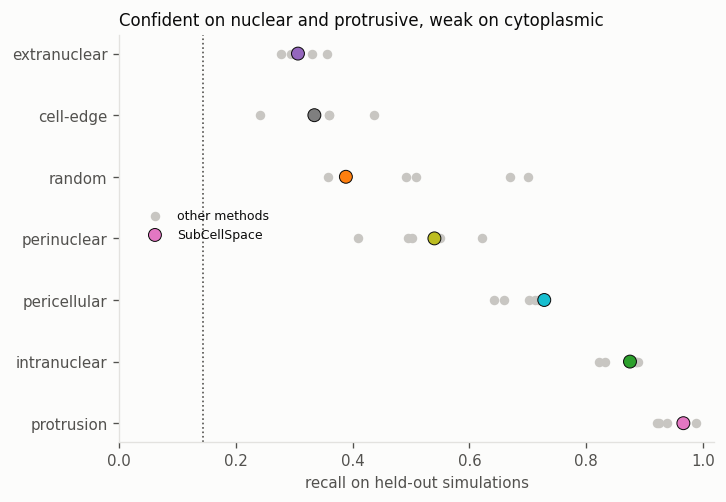

In [2]:
order = REC["subcellspace"].sort_values(ascending=False)
print("per-class recall, 7-class probe, held-out simulations")
print(REC.loc[order.index].rename(columns=LABELS).to_string(float_format=lambda v: f"{v:.3f}"))
others = REC.loc[["cell-edge", "extranuclear"], [m for m in REC.columns if m != "subcellspace"]]
print(f"\nbest other method on cell-edge or extranuclear: {others.values.max():.3f}")


def fig_profile():
    f, ax = plt.subplots(figsize=(6.4, 4.4))
    y = np.arange(len(order))
    for m in REC.columns:
        if m == "subcellspace": continue
        ax.scatter(REC.loc[order.index, m], y, s=22, color="#c8c6c2", zorder=2,
                   label="other methods" if m == REC.columns[1] else None)
    ax.scatter(order.values, y, s=60, color=[COL.get(p, "#888") for p in order.index],
               edgecolor=INK, linewidth=.6, zorder=3, label="SubCellSpace")
    ax.set_yticks(y); ax.set_yticklabels(order.index, fontsize=9)
    ax.set_xlabel("recall on held-out simulations"); ax.set_xlim(0, 1.02)
    ax.axvline(1/7, color=INK_MUTED, ls=":", lw=1)
    ax.annotate("chance", (1/7, len(order)-.4), xytext=(4, 0), textcoords="offset points",
                fontsize=7.5, color=INK_MUTED)
    ax.legend(fontsize=7.5, loc="upper left", bbox_to_anchor=(.02, .60))
    ax.set_title("Confident on nuclear and protrusive, weak on cytoplasmic", loc="left")
    f.savefig(FIG / "fig1_profile.png", dpi=200, bbox_inches="tight")
    return f

fig_profile();

`intranuclear` and `protrusion` are recovered at 0.88 and 0.97; `cell-edge` and
`extranuclear` at 0.33 and 0.31, with `perinuclear` and `random` not far above. Every other
representation is as weak on `cell-edge` and `extranuclear` (none above 0.44), which is what
we would expect if the categories themselves overlap: `cell-edge` and `perinuclear` are
sub-regions of extranuclear space. `pericellular` is recovered at 0.728.

## 2. Why recall is 0.31

A gene is called when a Bonferroni-corrected KS test passes **and** its earth mover's
distance (EMD) clears a cut. The two filters fail for different reasons, so the first step
is to count how many localised genes each one removes.

                                 stage   n  recall
                    labelled positives 224  1.0000
clear the Bonferroni-corrected KS gate 112  0.5000
          also clear earth_dist > 0.06  69  0.3080

gate is a power filter: median observations 34,975 (passers) vs 854 (failers), Mann-Whitney p=2.0e-15
abundance vs p-value: Spearman rho -0.57; abundance vs effect size: -0.02


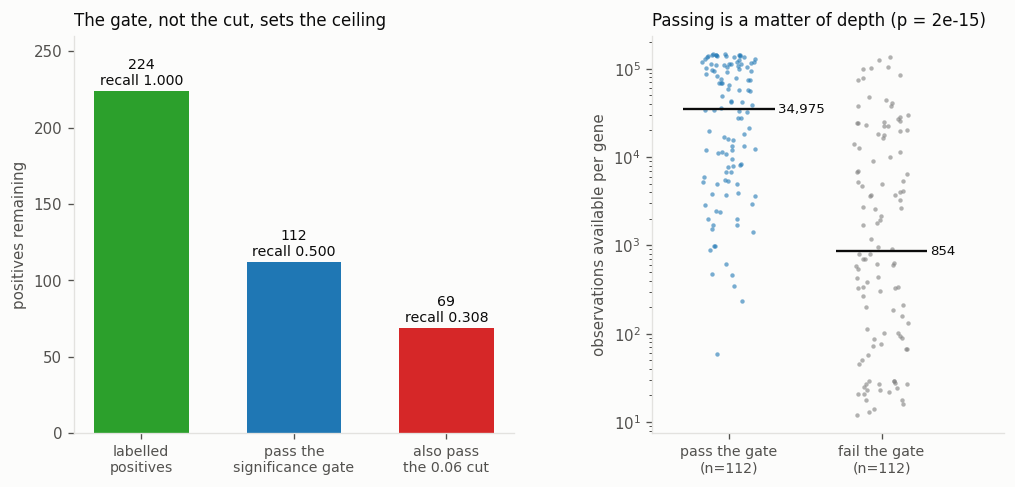

In [3]:
N_GENES = len(G)
G["ks"] = G.pval * N_GENES < 0.05                    # Bonferroni over the 250-gene panel
POS = G[~G.true_random.astype(bool)]
WF = pd.DataFrame({"stage": ["labelled positives", "clear the Bonferroni-corrected KS gate",
                             "also clear earth_dist > 0.06"],
                   "n": [len(POS), int(POS.ks.sum()), int((POS.ks & (POS.earth_dist > 0.06)).sum())]})
WF["recall"] = WF.n / len(POS)
print(WF.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
dep_pass = POS.loc[POS.ks, "total_obs_avail"]; dep_fail = POS.loc[~POS.ks, "total_obs_avail"]
mw_p = mannwhitneyu(dep_pass, dep_fail, alternative="two-sided").pvalue
print(f"\ngate is a power filter: median observations {dep_pass.median():,.0f} (passers) vs "
      f"{dep_fail.median():,.0f} (failers), Mann-Whitney p={mw_p:.1e}")
print(f"abundance vs p-value: Spearman rho {spearmanr(POS.total_obs_avail, POS.pval)[0]:+.2f}; "
      f"abundance vs effect size: {spearmanr(POS.total_obs_avail, POS.earth_dist)[0]:+.2f}")


def fig_recall():
    f, axes = plt.subplots(1, 2, figsize=(10.0, 4.3),
                           gridspec_kw={"width_ratios": [1, 0.8], "wspace": 0.35})
    ax = axes[0]
    n = WF.n.values
    ax.bar(np.arange(3), n, color=[OK, ACC, WARN], width=.62)
    for i, (v, r) in enumerate(zip(n, WF.recall)):
        ax.text(i, v + 4, f"{v}\nrecall {r:.3f}", ha="center", fontsize=8.5, color=INK)
    ax.set_xticks(range(3))
    ax.set_xticklabels(["labelled\npositives", "pass the\nsignificance gate",
                        "also pass\nthe 0.06 cut"], fontsize=8.5)
    ax.set_ylabel("positives remaining"); ax.set_ylim(0, 260)
    ax.set_title("The gate, not the cut, sets the ceiling", loc="left")

    ax = axes[1]
    rng = np.random.RandomState(3)
    for i, (d, c) in enumerate(((dep_pass, ACC), (dep_fail, "#7f7f7f"))):
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(d)), d, s=7, color=c, alpha=0.6, linewidths=0)
        ax.hlines(d.median(), i - 0.3, i + 0.3, color=INK, lw=1.4)
        ax.annotate(f"{d.median():,.0f}", (i + 0.32, d.median()), va="center", fontsize=8, color=INK)
    ax.set_yscale("log")
    ax.set_xticks([0, 1]); ax.set_xticklabels([f"pass the gate\n(n={len(dep_pass)})",
                                               f"fail the gate\n(n={len(dep_fail)})"], fontsize=8.5)
    ax.set_xlim(-0.5, 1.8); ax.set_ylabel("observations available per gene")
    ax.set_title(f"Passing is a matter of depth (p = {mw_p:.0e})", loc="left")
    f.savefig(FIG / "fig2_recall.png", dpi=200, bbox_inches="tight")
    return f

fig_recall();

The ceiling is the significance gate. Removing the EMD cut entirely would take recall to
0.50 and no further, because the other 112 localised genes never reach significance. What
decides significance is how much data a gene provides rather than how strongly it is
localised: abundance correlates with the p-value at ρ = −0.57 but with the measured effect
size at ρ = −0.02.

## Supplementary Figure 2

The page as published, drawn from the same data.

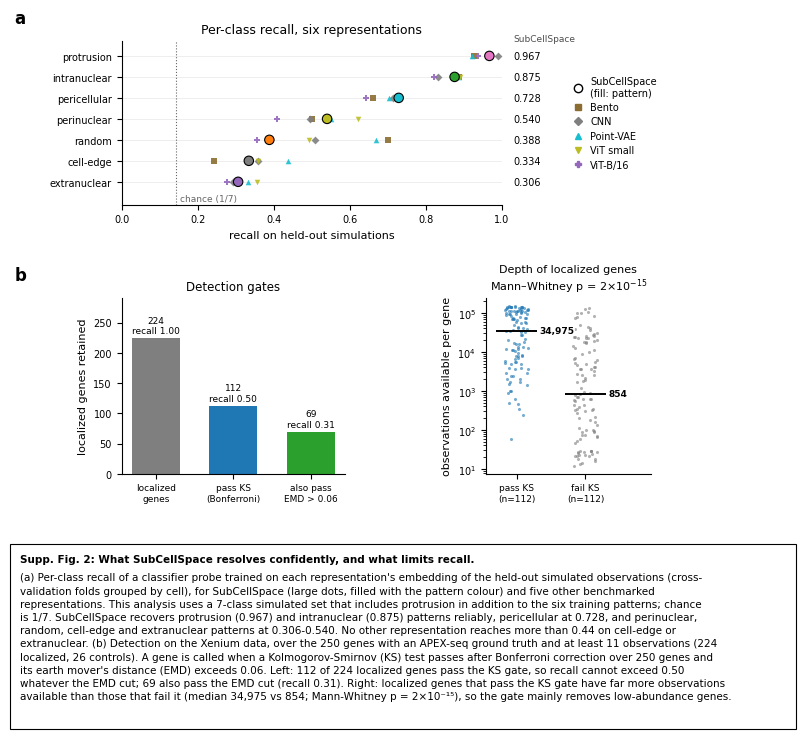

In [4]:
from matplotlib.lines import Line2D
from supp_style import new_page, panel_letter, caption_box, save_page, COL

# page labels and the quantities above, under the names the page uses
METHODS = LABELS
order = REC["subcellspace"].sort_values(ascending=False).index
N_GENES, N_NEG = len(G), int(G.true_random.sum())
n_pos, n_ks = len(POS), int(POS.ks.sum())
n_emd = int((POS.ks & (POS.earth_dist > 0.06)).sum())

# ================================================================ page
fig = new_page()

# a: per-class recall, six methods
ax_a = fig.add_axes([0.16, 0.815, 0.46, 0.14])
y = np.arange(len(order))[::-1]
MCOL = {"bento_features": "#8c6d31", "cnn_baseline": "#7f7f7f", "pointnet_vae_64": "#17becf",
        "subcellspace_vit": "#bcbd22", "subcellspace_vit_b16": "#9467bd"}
MMARK = {"bento_features": "s", "cnn_baseline": "D", "pointnet_vae_64": "^",
         "subcellspace_vit": "v", "subcellspace_vit_b16": "P"}
for yi in y:
    ax_a.axhline(yi, color="0.92", lw=0.6, zorder=0)
for m, c in MCOL.items():
    ax_a.scatter(REC.loc[order, m], y, s=16, marker=MMARK[m], color=c, alpha=0.9, zorder=2,
                 linewidths=0, label=METHODS[m])
ax_a.scatter(REC.loc[order, "subcellspace"], y, s=46, color=[COL[p] for p in order],
             edgecolors="black", linewidths=0.8, zorder=3)
for yi, v in zip(y, REC.loc[order, "subcellspace"]):
    ax_a.text(1.03, yi, f"{v:.3f}", va="center", ha="left", fontsize=7)
ax_a.text(1.03, len(order) - 0.2, "SubCellSpace", fontsize=6.5, ha="left", va="center",
          color="0.3")
ax_a.axvline(1 / 7, color="0.4", ls=":", lw=0.8)
ax_a.text(1 / 7 + 0.01, -0.8, "chance (1/7)", fontsize=6.5, color="0.4", va="center")
ax_a.set_yticks(y); ax_a.set_yticklabels(order)
ax_a.set_xlim(0, 1.0); ax_a.set_ylim(-1.1, len(order) - 0.3)
ax_a.set_xlabel("recall on held-out simulations")
ax_a.set_title("Per-class recall, six representations")
ax_a.spines[["top", "right"]].set_visible(False)
h = [Line2D([], [], marker="o", ls="", ms=6, markerfacecolor="white", markeredgecolor="black",
            label="SubCellSpace\n(fill: pattern)")]
h += [Line2D([], [], marker=MMARK[m], ls="", ms=4.5, color=c, label=METHODS[m])
      for m, c in MCOL.items()]
ax_a.legend(handles=h, loc="center left", bbox_to_anchor=(1.15, 0.5), frameon=False,
            handletextpad=0.3, labelspacing=0.45)
panel_letter(fig, ax_a, "a", dx=-0.13)

# b: recall breakdown on Xenium (gates) + depth of passers / failers
ax_b = fig.add_axes([0.16, 0.585, 0.27, 0.15])
vals = [n_pos, n_ks, n_emd]
ax_b.bar(range(3), vals, color=["#7f7f7f", "#1f77b4", "#2ca02c"], width=0.62)
for i, v in enumerate(vals):
    ax_b.text(i, v + 5, f"{v}\nrecall {v / n_pos:.2f}", ha="center", va="bottom", fontsize=6.5)
ax_b.set_xticks(range(3))
ax_b.set_xticklabels(["localized\ngenes", "pass KS\n(Bonferroni)", "also pass\nEMD > 0.06"],
                     fontsize=6.5)
ax_b.set_ylim(0, 290); ax_b.set_ylabel("localized genes retained")
ax_b.set_title("Detection gates", fontsize=8.5)
ax_b.spines[["top", "right"]].set_visible(False)
panel_letter(fig, ax_b, "b", dx=-0.13)

ax_b2 = fig.add_axes([0.60, 0.585, 0.20, 0.15])
rng = np.random.RandomState(3)
for i, (d, c) in enumerate(((dep_pass, "#1f77b4"), (dep_fail, "#7f7f7f"))):
    ax_b2.scatter(i + rng.uniform(-0.18, 0.18, len(d)), d, s=5, color=c, alpha=0.6, linewidths=0)
    ax_b2.hlines(d.median(), i - 0.3, i + 0.3, color="black", lw=1.4)
    ax_b2.text(i + 0.33, d.median(), f"{d.median():,.0f}", ha="left", va="center", fontsize=6.5, zorder=5,
               bbox=dict(fc="white", ec="none", pad=0.6, alpha=0.85),
               weight="bold")
ax_b2.set_yscale("log")
ax_b2.set_xticks([0, 1]); ax_b2.set_xticklabels([f"pass KS\n(n={len(dep_pass)})",
                                                 f"fail KS\n(n={len(dep_fail)})"], fontsize=6.5)
ax_b2.set_xlim(-0.45, 1.95)
ax_b2.set_ylabel("observations available per gene")
mant, ex = f"{mw_p:.0e}".split("e")
ax_b2.set_title(f"Depth of localized genes\nMann–Whitney p = {mant}×10$^{{{int(ex)}}}$", fontsize=8)
ax_b2.spines[["top", "right"]].set_visible(False)

r = REC["subcellspace"]
weak = r[["perinuclear", "random", "cell-edge", "extranuclear"]]
others = REC.loc[["cell-edge", "extranuclear"], [m for m in METHODS if m != "subcellspace"]].values
sup = lambda n: str(n).translate(str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹"))
expo = f"{mw_p:.0e}".split("e")
caption_box(fig, 0.525,
    "Supp. Fig. 2: What SubCellSpace resolves confidently, and what limits recall.",
    "(a) Per-class recall of a classifier probe trained on each representation's embedding of the held-out "
    "simulated observations (cross-validation folds grouped by cell), for SubCellSpace (large dots, filled "
    "with the pattern colour) and five other benchmarked representations. This analysis uses a 7-class simulated set "
    "that includes protrusion in addition to the six training patterns; chance is 1/7. SubCellSpace recovers "
    f"protrusion ({r['protrusion']:.3f}) and intranuclear ({r['intranuclear']:.3f}) patterns reliably, "
    f"pericellular at {r['pericellular']:.3f}, and perinuclear, random, cell-edge and extranuclear patterns at "
    f"{weak.min():.3f}-{weak.max():.3f}. No other representation reaches more than {others.max():.2f} on cell-edge or "
    "extranuclear. "
    f"(b) Detection on the Xenium data, over the {N_GENES} genes with an APEX-seq ground truth and at least 11 "
    f"observations ({n_pos} localized, {N_NEG} controls). A gene is called when a Kolmogorov-Smirnov (KS) test "
    f"passes after Bonferroni correction over {N_GENES} genes and its earth mover's distance (EMD) exceeds 0.06. "
    f"Left: {n_ks} of {n_pos} localized genes pass the KS gate, so recall cannot exceed {n_ks / n_pos:.2f} whatever the "
    f"EMD cut; {n_emd} also pass the EMD cut (recall {n_emd / n_pos:.2f}). Right: localized genes that pass the KS gate "
    f"have far more observations available than those that fail it (median {dep_pass.median():,.0f} vs "
    f"{dep_fail.median():,.0f}; Mann-Whitney p = {expo[0]}×10{sup(int(expo[1]))}), so the gate mainly removes "
    "low-abundance genes.", width_chars=134, fontsize=7.5)
save_page(fig, "2_pattern_confidence_and_recall_total")
fig
